In [ ]:
# AI-use disclosure 
# The code in this repository (src/covidphylo, scripts/, notebooks/) was drafted with Claude (Anthropic).
# I  ran it, checked the results against simulated ground truth and the unit tests (pytest),
# and am responsible for everything submitted.


# Project A - Benchmarking phylogenetic tree algorithms on SARS-CoV-2 (Pango-labelled) genomes

Shared core: `src/covidphylo` (identical to Project B). This notebook only adds the **benchmark harness**
(timing, size ladder, replicates, accuracy metrics, statistics).

**Question:** how do distance (NJ, UPGMA) and likelihood (FastTree, IQ-TREE, RAxML-NG) methods trade speed
against accuracy on near-identical SARS-CoV-2 genomes?

Set `MODE = "sim"` (ground-truth tree known; runs anywhere) or `MODE = "real"` (needs `data/` files from
`scripts/fetch_data.sh`).

In [15]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():            # allow running from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import os
#disable if too slow or decrease REPS, 10 is too slow on my machine
os.environ["PATH"] += os.pathsep + os.getcwd() + r"\phylo-tools"

## 1. Parameters (every value is a documented choice - see README table)

In [17]:
MODE   = "sim"                    # "sim" | "real"
SIZES  = [50, 100, 200] #, 400]      # size ladder (tips); extend to 1000+ on real data
REPS   = 5                       # replicate datasets per size (use >=10 for the report)
SEED   = 0
THREADS = 1                       # 1 thread each => fair timing
OUT = ROOT / "results" / "benchmark_notebook"
OUT.mkdir(parents=True, exist_ok=True)

from covidphylo import bench
from covidphylo.infer import available_methods
METHODS = available_methods()     # internal NJ/UPGMA always; FastTree/IQ-TREE/RAxML-NG if installed
print("methods available here:", METHODS)

methods available here: ['nj_jc', 'nj_p', 'upgma_jc', 'fasttree', 'iqtree']


## 2. Build the dataset factory

In [19]:
if MODE == "sim":
    factory = bench.sim_factory(length=29_903, rate=1e-3)
else:
    from covidphylo import qc
    from covidphylo.seqio import Alignment
    from covidphylo.tree import Tree
    aln = Alignment.from_fasta(ROOT / "data" / "subsample" / "aligned.fasta")        # reference-coordinate alignment
    aln = aln.subset([i for i, n in enumerate(aln.names) if n != "NC_045512.2"])      # drop the reference row
    vcf = ROOT / "data" / "problematic_sites_sarsCov2.vcf"
    sites = qc.build_mask(aln.length, qc.read_problematic_sites_vcf(vcf) if vcf.exists() else None)
    aln = qc.drop_ambiguous(aln.mask_sites(sites), 0.05)
    aln, _ = qc.deduplicate(aln)
    meta = qc.read_metadata(ROOT / "data" / "metadata.tsv")
    ref_path = ROOT / "data" / "usher_subtree.nwk"
    ref = Tree.from_newick(ref_path.read_text()) if ref_path.exists() else None
    factory = bench.real_factory(aln, meta, ref)

## 3. Run (every method sees the same dataset within a replicate)

In [21]:
df = bench.run_benchmark(factory, SIZES, REPS, METHODS, workdir=OUT / "work", seed0=SEED,
                         threads=THREADS, verbose=True)
df.to_csv(OUT / "benchmark_results.csv", index=False)
df.head()

nj_jc     n=   50 rep=0     0.02s nRF*=0.095
nj_p      n=   50 rep=0     0.02s nRF*=0.095
upgma_jc  n=   50 rep=0     0.02s nRF*=0.378
fasttree  n=   50 rep=0    31.64s nRF*=0.119
iqtree    n=   50 rep=0     0.41s nRF*=0.119
nj_jc     n=   50 rep=1     0.02s nRF*=0.093
nj_p      n=   50 rep=1     0.02s nRF*=0.093
upgma_jc  n=   50 rep=1     0.02s nRF*=0.556
fasttree  n=   50 rep=1    29.12s nRF*=0.082
iqtree    n=   50 rep=1     0.41s nRF*=0.093
nj_jc     n=   50 rep=2     0.02s nRF*=0.047
nj_p      n=   50 rep=2     0.02s nRF*=0.047
upgma_jc  n=   50 rep=2     0.02s nRF*=0.506
fasttree  n=   50 rep=2    32.27s nRF*=0.035
iqtree    n=   50 rep=2     0.42s nRF*=0.047
nj_jc     n=   50 rep=3     0.02s nRF*=0.122
nj_p      n=   50 rep=3     0.02s nRF*=0.122
upgma_jc  n=   50 rep=3     0.02s nRF*=0.528
fasttree  n=   50 rep=3    34.43s nRF*=0.086
iqtree    n=   50 rep=3     0.42s nRF*=0.086
nj_jc     n=   50 rep=4     0.02s nRF*=0.048
nj_p      n=   50 rep=4     0.02s nRF*=0.048
upgma_jc  

,method,n_tips,rep,seed,wall_s,peak_mb,mem_source,nrf,nrf_collapsed,patristic_r,lineage_auc,lineage_monophyly
0,nj_jc,50,0,50000,0.017374,3.014056,tracemalloc,0.148936,0.095238,0.938743,0.959703,0.9
1,nj_p,50,0,50000,0.018077,3.159595,tracemalloc,0.148936,0.095238,0.938760,0.959700,0.9
2,upgma_jc,50,0,50000,0.015596,3.014056,tracemalloc,0.404255,0.377778,0.809873,0.974655,0.7
3,fasttree,50,0,50000,31.643951,NaN,none,0.085106,0.119048,0.939607,0.958161,1.0
4,iqtree,50,0,50000,0.409644,NaN,none,0.127660,0.119048,0.939643,0.960707,0.9


## 4. Summary with 95% confidence intervals

In [23]:
S = bench.summarise(df)
S.to_csv(OUT / "benchmark_summary.csv", index=False)
S[["method", "n_tips", "reps", "wall_s", "nrf_collapsed", "patristic_r", "lineage_auc"]].round(4)

,method,n_tips,reps,wall_s,nrf_collapsed,patristic_r,lineage_auc
0,fasttree,50,5,31.9052,0.0741,0.9425,0.9344
1,iqtree,50,5,0.4084,0.0785,0.9425,0.9362
2,nj_jc,50,5,0.0192,0.0809,0.9421,0.9354
3,nj_p,50,5,0.0176,0.0809,0.9421,0.9353
4,upgma_jc,50,5,0.0171,0.5312,0.7546,0.9320
5,fasttree,100,5,69.4444,0.0685,0.9398,0.9546
6,iqtree,100,5,1.0396,0.0649,0.9397,0.9559
7,nj_jc,100,5,0.0694,0.0659,0.9394,0.9552
8,nj_p,100,5,0.0483,0.0637,0.9394,0.9552
9,upgma_jc,100,5,0.0456,0.4940,0.7780,0.9545


## 5. Figures
`nrf_collapsed` = normalised Robinson-Foulds after contracting branches with < 0.5 expected mutations in both trees;
without this, arbitrary resolution of polytomies dominates the score for SARS-CoV-2.

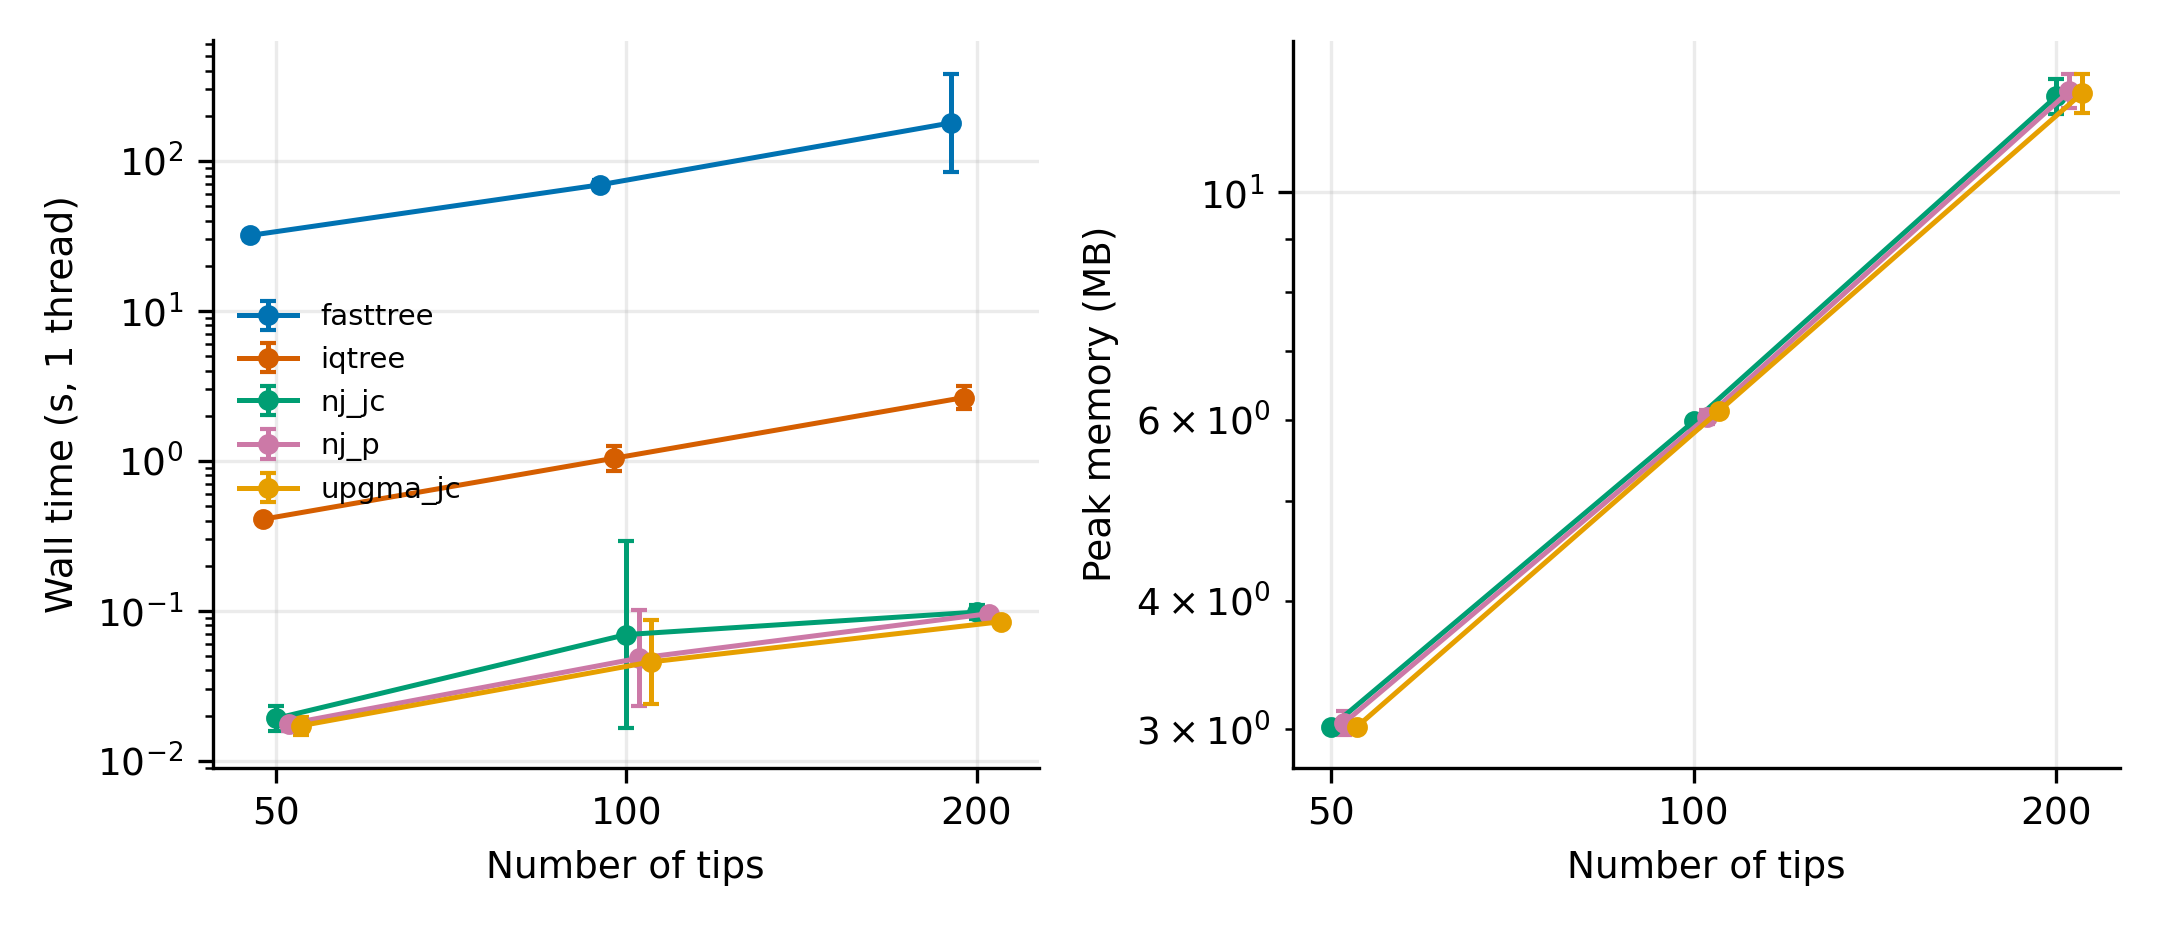

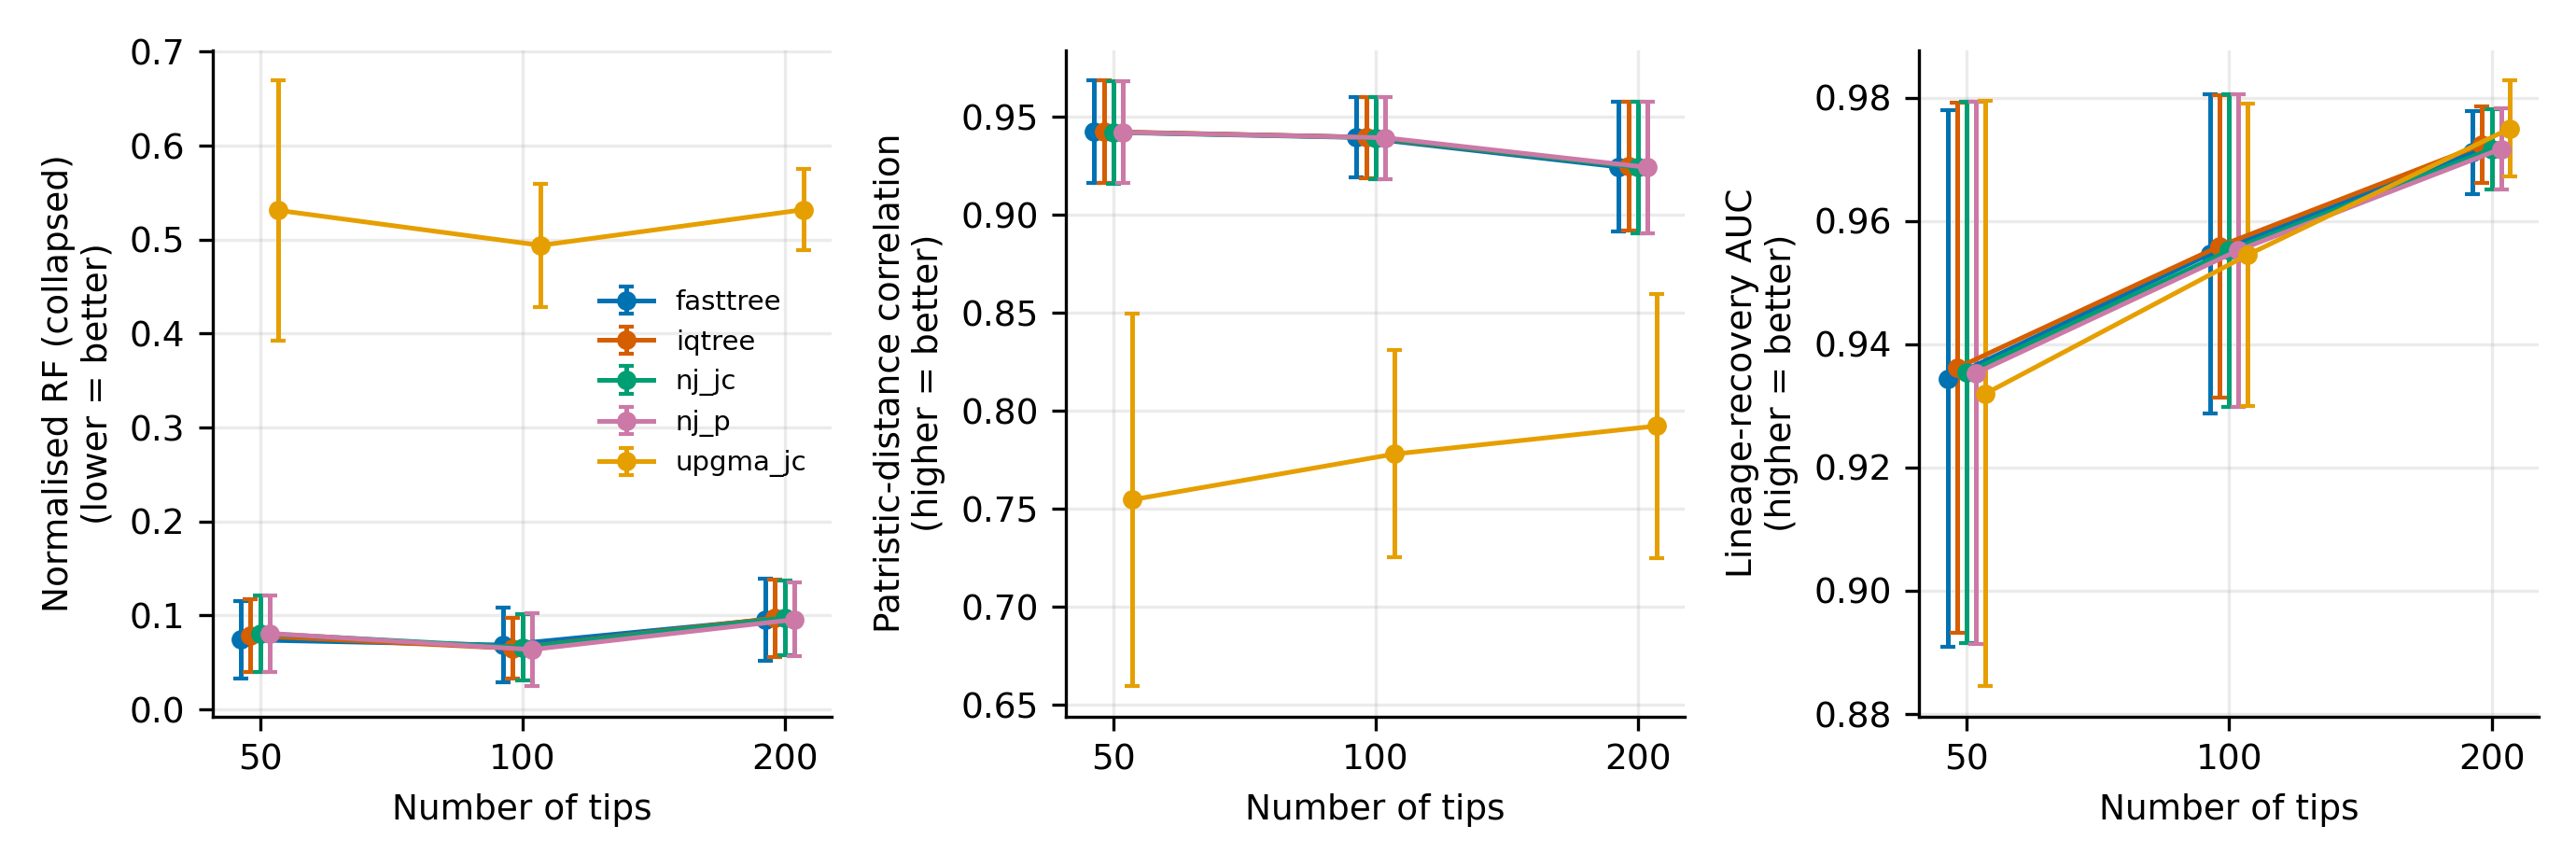

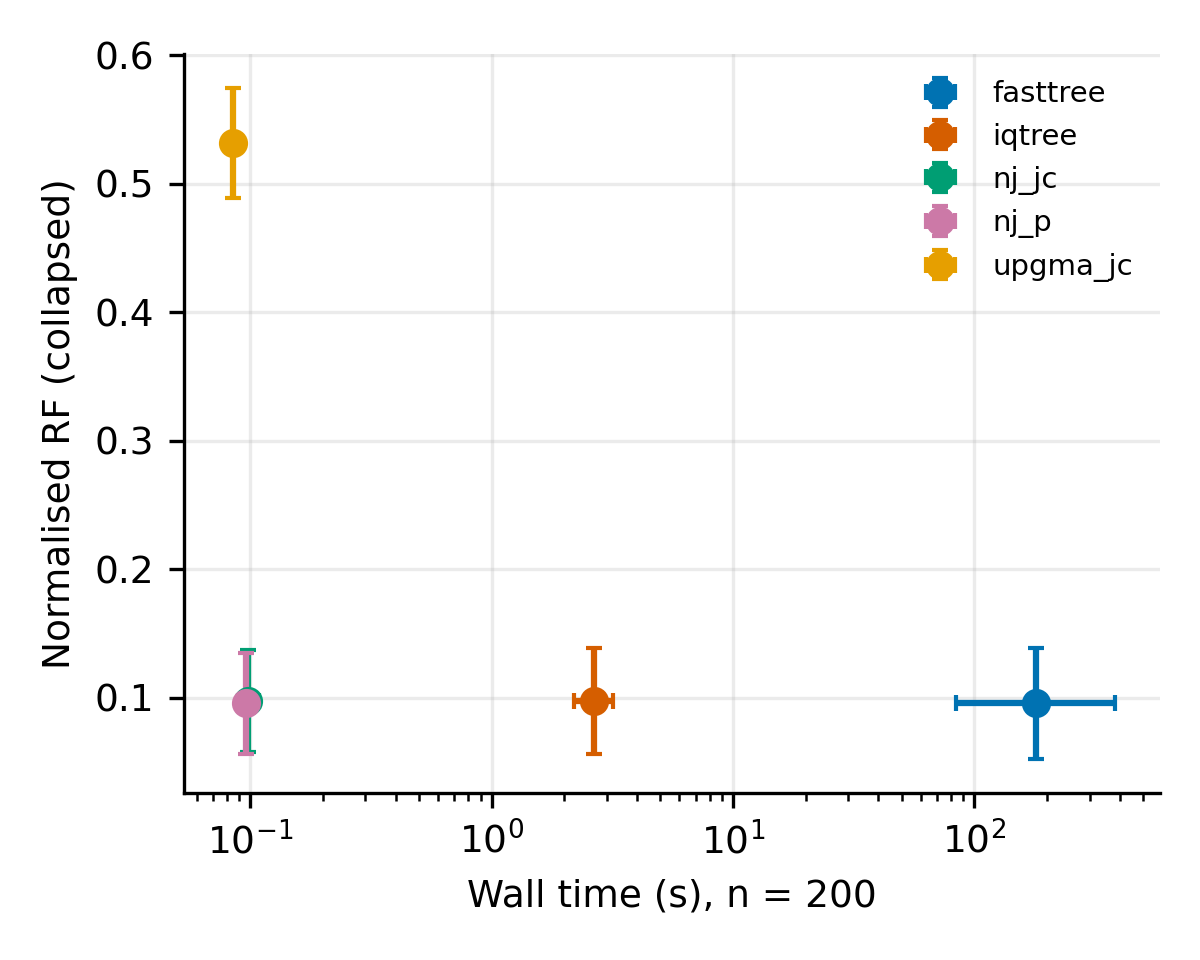

In [25]:
for f in bench.plot_benchmark(df, OUT):
    display(Image(str(f)))

## 6. Paired significance tests (Wilcoxon signed-rank, Holm-adjusted)

In [27]:
tests = pd.concat([bench.paired_tests(df, m, at_n=max(SIZES)) for m in ("nrf_collapsed", "wall_s")])
tests.to_csv(OUT / "paired_tests.csv", index=False)
tests.round(4)

,metric,at_n,a,b,n_pairs,n_nonzero,min_possible_p,p,mean_diff_a_minus_b,a_lower_in,b_lower_in,p_holm,fold_change_a_over_b
0,nrf_collapsed,200,fasttree,iqtree,5,4,0.1250,0.6250,-0.0017,3,1,1.0000,NaN
1,nrf_collapsed,200,fasttree,nj_jc,5,5,0.0625,0.3125,-0.0019,3,2,1.0000,NaN
2,nrf_collapsed,200,fasttree,nj_p,5,5,0.0625,0.8125,-0.0001,3,2,1.0000,NaN
3,nrf_collapsed,200,fasttree,upgma_jc,5,5,0.0625,0.0625,-0.4364,5,0,0.6250,NaN
4,nrf_collapsed,200,iqtree,nj_jc,5,3,0.2500,1.0000,-0.0002,1,2,1.0000,NaN
5,nrf_collapsed,200,iqtree,nj_p,5,4,0.1250,0.3750,0.0017,1,3,1.0000,NaN
6,nrf_collapsed,200,iqtree,upgma_jc,5,5,0.0625,0.0625,-0.4347,5,0,0.6250,NaN
7,nrf_collapsed,200,nj_jc,nj_p,5,2,0.5000,0.5000,0.0018,0,2,1.0000,NaN
8,nrf_collapsed,200,nj_jc,upgma_jc,5,5,0.0625,0.0625,-0.4345,5,0,0.6250,NaN
9,nrf_collapsed,200,nj_p,upgma_jc,5,5,0.0625,0.0625,-0.4364,5,0,0.6250,NaN


## 7. Interpretation checklist (for the report)
* Which method is on the speed-accuracy Pareto front at the largest n?
* Does accuracy degrade with n, and is the CI width shrinking with replicates?
* Limitations: simulated data under K80+Gamma favour distance methods less than real recombinant data would;
  Pango lineages are *derived from* trees, so lineage recovery is a proxy, not ground truth.